# 01 · PyTorch foundations for transformers

**Goal:** get fluent with the five PyTorch ideas that every later notebook
leans on — tensors, shapes/broadcasting, autograd, `nn.Module`, and the
training loop. Everything is demonstrated on tensors small enough to print.

**You will be able to:**
1. read a shape annotation like `(B, T, C)` and predict the output shape of an op
2. explain what `.backward()` actually computes
3. write a training loop from scratch and know what each line is for
4. move work onto a GPU (CUDA or Apple MPS) without changing the model code

Prerequisites: Python, and the vague memory that a derivative measures slope.

In [2]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

print("torch", torch.__version__)

torch 2.5.1+cu121


## 0 · Bootstrap: shared course helpers

The repo ships a small `course_utils.py` with data loading, batching and
plotting so later notebooks don't re-type them. Nothing in it is magic; each
helper is introduced in the notebook where the concept first appears.

In [3]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "course_utils.py").exists():
    ROOT = ROOT.parent          # running from notebooks/
sys.path.insert(0, str(ROOT))

import course_utils as cu

cu.set_seed(1337)
device = cu.get_device()
print("device:", cu.describe_device(device))

device: cuda (NVIDIA GeForce RTX 2060)


## 1 · Tensors are typed, shaped, device-resident arrays

A tensor carries three things you must always be aware of: its **shape**, its
**dtype**, and its **device**. Most beginner bugs are one of these three being
not what you assumed.

In [4]:
a = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print(a)
print("shape:", a.shape, "| dtype:", a.dtype, "| device:", a.device)

ints = torch.tensor([1, 2, 3])            # int64 — the dtype of *token ids*
print("ints dtype:", ints.dtype)

# Common constructors
print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.arange(6))                    # 0..5
print(torch.randn(2, 3))                  # standard normal
print(torch.randint(0, 10, (2, 3)))       # random ints, like fake token ids

tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3]) | dtype: torch.float32 | device: cpu
ints dtype: torch.int64
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([0, 1, 2, 3, 4, 5])
tensor([[-2.0260, -2.0655, -1.2054],
        [-0.9122, -1.2502,  0.8032]])
tensor([[7, 6, 0],
        [8, 1, 4]])


### dtype matters

- **`int64` (long)** — token ids, indices, targets for `cross_entropy`.
- **`float32`** — the default for weights and activations.
- **`bfloat16` / `float16`** — half precision used for fast training (notebook 09).
- **`bool`** — masks.

Mixing them silently upcasts, or loudly errors. Embedding layers *require*
`int64` input, and `cross_entropy` *requires* `int64` targets.

In [5]:
try:
    nn.Embedding(10, 4)(torch.tensor([1.0, 2.0]))   # float ids -> error
except Exception as exc:
    print(type(exc).__name__, "->", str(exc)[:90])

RuntimeError -> Expected tensor for argument #1 'indices' to have one of the following scalar types: Long,


## 2 · Shapes: the language of this course

From here on, tensors are annotated with letters:

| letter | meaning | typical value |
|---|---|---|
| `B` | batch size — independent sequences processed together | 32 |
| `T` | time / sequence length (number of tokens) | 64–1024 |
| `C` | channels, a.k.a. `d_model`, the width of the residual stream | 128–4096 |
| `h` | number of attention heads | 4–32 |
| `d` | head dimension = `C // h` | 32–128 |
| `V` | vocabulary size | 47–128k |

The whole transformer is a sequence of shape transformations. If you can track
shapes, you can read any implementation.

In [6]:
B, T, C = 2, 5, 8
x = torch.randn(B, T, C)
print("x", tuple(x.shape))

# A Linear layer maps only the LAST dimension: (..., C) -> (..., out)
lin = nn.Linear(C, 16)
print("Linear(C,16)(x)", tuple(lin(x).shape))        # (B, T, 16)

# view/reshape reinterprets memory: total element count must match
print("x.view(B*T, C)", tuple(x.view(B * T, C).shape))

# transpose swaps two dims (no copy, just a stride change)
print("x.transpose(0, 1)", tuple(x.transpose(0, 1).shape))   # (T, B, C)

# unsqueeze inserts a size-1 dim; squeeze removes one
print("x.unsqueeze(1)", tuple(x.unsqueeze(1).shape))         # (B, 1, T, C)

x (2, 5, 8)
Linear(C,16)(x) (2, 5, 16)
x.view(B*T, C) (10, 8)
x.transpose(0, 1) (5, 2, 8)
x.unsqueeze(1) (2, 1, 5, 8)


### `view` vs `reshape`, and why `.contiguous()` shows up

`view` needs the memory layout to be compatible; after a `transpose`, it often
isn't, and you must call `.contiguous()` first (this is exactly the line you'll
see in multi-head attention when heads are merged back together).

In [7]:
y = x.transpose(1, 2)                     # (B, C, T), non-contiguous
print("is_contiguous:", y.is_contiguous())
try:
    y.view(B, -1)
except Exception as exc:
    print("view failed:", str(exc)[:80])
print("works after contiguous:", tuple(y.contiguous().view(B, -1).shape))
print("reshape just handles it:", tuple(y.reshape(B, -1).shape))

is_contiguous: False
view failed: view size is not compatible with input tensor's size and stride (at least one di
works after contiguous: (2, 40)
reshape just handles it: (2, 40)


## 3 · Broadcasting

Two shapes are compatible if, aligned from the **right**, each dimension pair
is equal or one of them is 1. Size-1 dims are virtually repeated.

This is why a positional embedding of shape `(T, C)` can be added to token
embeddings of shape `(B, T, C)`, and why a causal mask of shape
`(1, 1, T, T)` can be applied to attention scores of shape `(B, h, T, T)`.

In [8]:
tok = torch.randn(B, T, C)        # (B, T, C)
pos = torch.randn(T, C)           # (T, C) -> broadcast to (B, T, C)
print("tok + pos:", tuple((tok + pos).shape))

scores = torch.randn(B, 4, T, T)  # (B, h, T, T)
mask = torch.tril(torch.ones(T, T)).view(1, 1, T, T)
print("mask broadcast:", tuple((scores * mask).shape))

# A classic bug: (T,) + (T, 1) silently becomes (T, T)
v = torch.arange(4.0)
print((v + v.unsqueeze(1)).shape, "<- probably not what you wanted")

tok + pos: (2, 5, 8)
mask broadcast: (2, 4, 5, 5)
torch.Size([4, 4]) <- probably not what you wanted


## 4 · Matrix multiplication and `@`

`@` (`torch.matmul`) multiplies the **last two** dimensions and broadcasts
everything to the left of them. That single rule powers batched multi-head
attention: `(B, h, T, d) @ (B, h, d, T) -> (B, h, T, T)`.

In [9]:
q = torch.randn(B, 4, T, 16)      # (B, h, T, d)
k = torch.randn(B, 4, T, 16)      # (B, h, T, d)
att = q @ k.transpose(-2, -1)     # (B, h, T, T)
print("attention scores:", tuple(att.shape))

v_ = torch.randn(B, 4, T, 16)
print("att @ v:", tuple((att @ v_).shape))          # (B, h, T, d)

attention scores: (2, 4, 5, 5)
att @ v: (2, 4, 5, 16)


## 5 · Softmax and cross-entropy

`softmax` turns a vector of scores into a probability distribution over the
last dimension. `cross_entropy` measures how surprised the model is by the
true label: `-log p(correct)`. It expects **raw logits**, not softmaxed
probabilities — it applies log-softmax internally for numerical stability.

In [10]:
logits = torch.tensor([[2.0, 1.0, 0.1]])
probs = F.softmax(logits, dim=-1)
print("probs:", probs, "sum:", probs.sum().item())

target = torch.tensor([0])                      # the correct class is index 0
print("cross_entropy:", F.cross_entropy(logits, target).item())
print("-log p(target):", -math.log(probs[0, 0].item()))

# Uniform predictions over V classes give loss = ln(V) — the "no knowledge"
# baseline you will compare every language model against.
V = 47
print(f"ln({V}) =", math.log(V))
print("uniform loss:", F.cross_entropy(torch.zeros(1, V), torch.tensor([3])).item())

probs: tensor([[0.6590, 0.2424, 0.0986]]) sum: 1.0000001192092896
cross_entropy: 0.4170299470424652
-log p(target): 0.4170299666528373
ln(47) = 3.8501476017100584
uniform loss: 3.8501474857330322


For sequence models we predict a token at **every** position, so logits are
`(B, T, V)` and targets are `(B, T)`. `cross_entropy` wants `(N, V)` and
`(N,)`, so we flatten — this exact two-line pattern appears in every model in
this course.

In [11]:
seq_logits = torch.randn(B, T, V)
seq_targets = torch.randint(0, V, (B, T))
loss = F.cross_entropy(seq_logits.view(-1, V), seq_targets.view(-1))
print("flattened:", tuple(seq_logits.view(-1, V).shape), tuple(seq_targets.view(-1).shape))
print("loss:", loss.item())

flattened: (10, 47) (10,)
loss: 4.580530166625977


## 6 · Autograd: what `.backward()` really does

Every tensor with `requires_grad=True` records the ops applied to it, forming
a graph. `.backward()` walks that graph in reverse, applying the chain rule,
and **accumulates** the result into each leaf's `.grad`.

Let's verify it against calculus by hand: for `y = 3x² + 2x`, `dy/dx = 6x + 2`,
which at `x = 4` is `26`.

In [12]:
x_ = torch.tensor(4.0, requires_grad=True)
y_ = 3 * x_ ** 2 + 2 * x_
y_.backward()
print("autograd grad:", x_.grad.item(), "| by hand:", 6 * 4 + 2)

autograd grad: 26.0 | by hand: 26


### Gradients accumulate — hence `zero_grad()`

Calling `.backward()` twice adds into `.grad`. Forgetting `opt.zero_grad()` is
the single most common silent training bug: your updates use the sum of all
gradients seen so far. (Notebook 09 shows the one case where you *want* this:
gradient accumulation.)

In [13]:
w = torch.tensor(1.0, requires_grad=True)
for i in range(3):
    (w * 2).backward()
    print(f"after backward #{i + 1}, w.grad =", w.grad.item())

w.grad = None                          # equivalent to zero_grad(set_to_none=True)
(w * 2).backward()
print("after reset:", w.grad.item())

after backward #1, w.grad = 2.0
after backward #2, w.grad = 4.0
after backward #3, w.grad = 6.0
after reset: 2.0


### Turning autograd off

For evaluation and generation you don't need gradients; skipping the graph
saves memory and time.

In [14]:
a_ = torch.randn(3, requires_grad=True)
print("grad tracked:", (a_ * 2).requires_grad)
with torch.no_grad():
    print("inside no_grad:", (a_ * 2).requires_grad)

grad tracked: True
inside no_grad: False


## 7 · `nn.Module`: parameters that PyTorch keeps track of

A `Module` is a container that (a) registers `nn.Parameter`s so an optimizer
can find them, (b) composes into trees, and (c) has a `forward` you invoke by
*calling* the module (`model(x)`, never `model.forward(x)` — hooks would be
skipped).

In [36]:
class MyLinear(nn.Module):
    """nn.Linear, written out, to demystify it: y = x @ W.T + b"""

    def __init__(self, in_features: int, out_features: int):
        super().__init__()                      # ALWAYS call this first
        self.weight = nn.Parameter(torch.randn(out_features, in_features) * 0.02)
        self.bias = nn.Parameter(torch.zeros(out_features))

    def forward(self, x):                       # (..., in) -> (..., out)
        return x @ self.weight.T + self.bias


m = MyLinear(4, 3)
print(m)
for name, p in m.named_parameters():
    print(f"  {name:8s} {tuple(p.shape)}  requires_grad={p.requires_grad}")
print("output:", tuple(m(torch.randn(2, 4)).shape))
print("param count:", cu.count_params(m))

MyLinear()
  weight   (3, 4)  requires_grad=True
  bias     (3,)  requires_grad=True
output: (2, 3)
param count: 15


### Buffers: state that is not learned

The causal mask in attention is not a parameter — it must move to the GPU with
the model and be saved in checkpoints, but it must never be updated. That is
exactly what `register_buffer` is for.

In [16]:
class WithBuffer(nn.Module):
    def __init__(self, T):
        super().__init__()
        self.register_buffer("mask", torch.tril(torch.ones(T, T)))

    def forward(self, x):
        return x * self.mask


wb = WithBuffer(4)
print("params:", list(dict(wb.named_parameters())), "buffers:", list(dict(wb.named_buffers())))
print(wb.mask)

params: [] buffers: ['mask']
tensor([[1., 0., 0., 0.],
        [1., 1., 0., 0.],
        [1., 1., 1., 0.],
        [1., 1., 1., 1.]])


### `train()` vs `eval()`

Dropout and normalization layers behave differently in the two modes. Calling
`model.eval()` before validation/generation — and `model.train()` after — is
not optional.

In [17]:
drop = nn.Dropout(0.5)
ones = torch.ones(8)
drop.train(); print("train mode:", drop(ones))     # random zeros, rest scaled up
drop.eval();  print("eval mode :", drop(ones))     # identity

train mode: tensor([0., 2., 0., 2., 0., 2., 2., 0.])
eval mode : tensor([1., 1., 1., 1., 1., 1., 1., 1.])


## 8 · The training loop, end to end

Let's fit a tiny MLP to a nonlinear function. Every language model in this
course uses the *same five lines*, only with a bigger model and a text batch.

In [33]:
cu.set_seed(0)

# Data: y = sin(3x) + noise
x_data = torch.rand(512, 1) * 2 - 1
y_data = torch.sin(3 * x_data) + 0.05 * torch.randn_like(x_data)

model = nn.Sequential(
    nn.Linear(1, 64), nn.Tanh(),
    nn.Linear(64, 64), nn.Tanh(),
    nn.Linear(64, 1),
)
opt = torch.optim.AdamW(model.parameters(), lr=1e-2)

losses = []
for step in range(600):
    pred = model(x_data)                     # 1. forward
    loss = F.mse_loss(pred, y_data)          # 2. loss
    #opt.zero_grad(set_to_none=True)          # 3. clear old gradients
    loss.backward()                          # 4. backward: fill .grad
    opt.step()                               # 5. update parameters
    losses.append(loss.item())
    if step % 150 == 0:
        print(f"step {step:4d} | mse {loss.item():.4f}")
print(f"final mse {losses[-1]:.4f}")

step    0 | mse 0.6700
step  150 | mse 50.9826
step  300 | mse 58.6411
step  450 | mse 1469.3744
final mse 704.5365


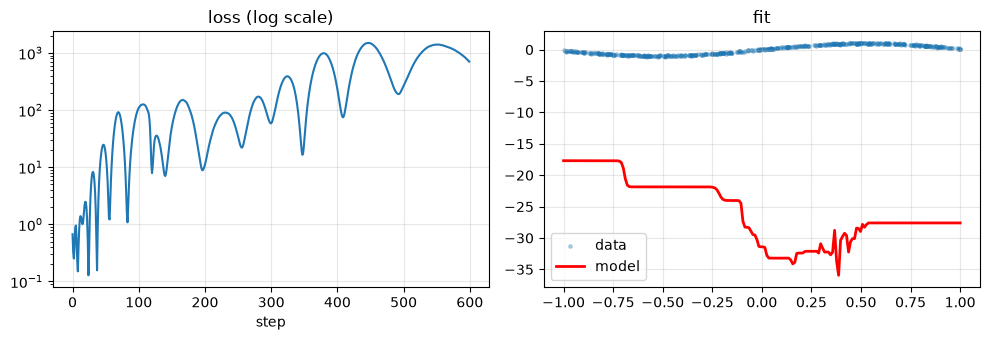

In [34]:
try:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(losses); axes[0].set_yscale("log")
    axes[0].set_title("loss (log scale)"); axes[0].set_xlabel("step")
    axes[0].grid(alpha=0.3)

    xs = torch.linspace(-1, 1, 200).unsqueeze(1)
    with torch.no_grad():
        axes[1].scatter(x_data, y_data, s=6, alpha=0.3, label="data")
        axes[1].plot(xs, model(xs), "r-", lw=2, label="model")
    axes[1].legend(); axes[1].set_title("fit"); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed — skipping plots")

## 9 · Devices

Model and data must live on the same device. The idiom is to pick a device
once and `.to(device)` both. Apple Silicon exposes `mps`; NVIDIA exposes
`cuda`. Nothing else about the model changes.

In [20]:
print("device:", cu.describe_device(device))
gpu_model = nn.Linear(4, 4).to(device)
inp = torch.randn(2, 4, device=device)
print("output device:", gpu_model(inp).device)

try:
    gpu_model(torch.randn(2, 4))              # CPU input into a non-CPU model
except Exception as exc:
    print("mismatch ->", type(exc).__name__, str(exc)[:80])

device: cuda (NVIDIA GeForce RTX 2060)
output device: cuda:0
mismatch -> RuntimeError Expected all tensors to be on the same device, but found at least two devices, c


## 10 · Two habits worth forming now

**Annotate shapes in comments.** `# (B, T, C) -> (B, h, T, d)` next to a
`view`/`transpose` will save you hours later.

**Assert what you assume.** A one-line assert catches a silently-broadcast
bug that would otherwise show up as "loss plateaus and I don't know why".

In [21]:
def scaled_dot_product_preview(q, k):
    assert q.shape == k.shape, f"{q.shape} != {k.shape}"
    B, h, T, d = q.shape
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(d)     # (B, h, T, T)
    assert scores.shape == (B, h, T, T)
    return scores


print(tuple(scaled_dot_product_preview(torch.randn(2, 4, 6, 16),
                                       torch.randn(2, 4, 6, 16)).shape))

(2, 4, 6, 6)


## 

Exercises

1. **Shape golf.** Starting from `x` of shape `(2, 6, 12)`, produce
   `(2, 3, 6, 4)` — i.e. split the channel dim into 3 heads of 4 — using only
   `view` and `transpose`. Then get back to `(2, 6, 12)`. (This is *exactly*
   the multi-head reshape from notebook 04.)
2. **Broadcast trap.** Predict the shape of `torch.randn(4, 1) + torch.randn(4)`
   before running it. Why is it a footgun in a loss function?
3. **Hand-check a gradient.** For `f(x) = log(1 + exp(x))` (softplus), the
   derivative is the sigmoid. Verify with autograd at `x = -2, 0, 2`.
4. **Break the loop.** Delete `opt.zero_grad()` from section 8 and re-run.
   Explain the curve you get.
5. **Init matters.** Change `MyLinear`'s init from `* 0.02` to `* 5.0`, stack
   six of them, and print the standard deviation of the activations after each
   layer. This previews why transformers need careful init and normalization.

---
**Next:** [02 · Language modeling and the bigram baseline](02_language_modeling_and_bigrams.ipynb) —
turn text into tensors and train the simplest possible language model, so that
attention has something to beat.

In [28]:
# Shape golf. Starting from x of shape (2, 6, 12), produce (2, 3, 6, 4) — i.e. split the channel dim into 3 heads of 4 — using only view and transpose. Then get back to (2, 6, 12). (This is exactly the multi-head reshape from notebook 04.)

x = torch.randn(2, 6, 12)
x = x.view(2, 6, 3, 4).transpose(2, 1)
print(x.shape)


x = x.transpose(2, 1)
x = x.view(2,  -1, 12)
print(x.shape)

torch.Size([2, 3, 6, 4])
torch.Size([2, 6, 12])


In [31]:
print((torch.randn(4, 1) + torch.randn(4)).shape)

torch.Size([4, 4])


In [ ]:
for i in range(-2, 0, 2)

In [32]:
x_inputs = [-2.0, 0.0, 2.0]

for val in x_inputs:
    # 1. Setup leaf tensor tracking gradients
    x = torch.tensor(val, requires_grad=True)
    
    # 2. Forward pass: Softplus
    y = torch.log(1 + torch.exp(x))
    
    # 3. Backward pass: Compute autograd derivative
    y.backward()
    
    # 4. Compute analytical formula directly
    analytical_grad = 1 / (1 + torch.exp(-torch.tensor(val)))
    
    print(f"At x = {val:2.0f} | Autograd: {x.grad.item():.4f} | Analytical: {analytical_grad.item():.4f}")

At x = -2 | Autograd: 0.1192 | Analytical: 0.1192
At x =  0 | Autograd: 0.5000 | Analytical: 0.5000
At x =  2 | Autograd: 0.8808 | Analytical: 0.8808
